# Technical noise: sequencing models, the sampling landscape and noise decomposition

A count matrix is not a matrix of molecule numbers. Each molecule is captured, reverse-transcribed, amplified and sequenced with some probability, and the counts we see are a thinned, noisy image of the transcriptional state. Monod models that thinning explicitly: a *sequencing model* sits between the transcriptional model and the data, with its own genome-wide parameters that are found by scanning a grid rather than fitted per gene. This notebook is about that layer.

**Data.** The fits use the Allen Institute mouse cortex data from the Monod paper: GABAergic and glutamatergic neurons from one sequencing run, with the poly(A)-based gene length reference. These files are not in the repository. The second cell looks for `example_h5ad/gaba_example.h5ad`, `example_h5ad/glu_example.h5ad` and `monod_examples/polyA_ref/...`; if the h5ad files are missing but a clone of [pachterlab/monod_examples](https://github.com/pachterlab/monod_examples) (branch `anndata`) sits at the repository root, they are rebuilt from its compressed chunks.

## Contents

1. What the sequencing models do: Poisson and Bernoulli sampling, and what they do to moments  
2. Gene length and the sampling grid  
3. The sampling landscape on the GABAergic data: optimum, valley, and the burst-size trade-off  
4. Noise decomposition: intrinsic, extrinsic and technical variance per gene  
5. Two cell types from one run: separate and shared optima  
6. Ambiguous assignments: the third channel  


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import os, sys, time, logging, warnings, functools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad

from monod.cme_toolbox import CMEModel
from monod.extract_data import extract_data, combine_chunks
from monod.inference import (InferenceParameters, perform_inference, reject_genes,
                             search_result_from_uns, find_shared_sampling_optimum)
from monod import analysis
import monod.inference as inference_module

logging.getLogger('monod').setLevel(logging.WARNING)
inference_module.tqdm = functools.partial(inference_module.tqdm, disable=True)   # no progress bars in the saved notebook
warnings.filterwarnings('ignore', category=FutureWarning)
os.makedirs('figures', exist_ok=True)

GABA = 'example_h5ad/gaba_example.h5ad'
GLU  = 'example_h5ad/glu_example.h5ad'
TX   = 'monod_examples/polyA_ref/gg_200524_mouse_genome_polyA_cum_1'
NUM_CORES = 8


# The example repository ships each h5ad as zlib-compressed chunks.
for path, chunks in [(GABA, 'monod_examples/sample_data/gaba_anndata'),
                     (GLU,  'monod_examples/sample_data/glu_anndata')]:
    if not os.path.exists(path) and os.path.isdir(chunks):
        combine_chunks(chunks, path)
for path in (GABA, GLU, TX):
    print(f'{path:<70} {"found" if os.path.exists(path) else "MISSING"}')


example_h5ad/gaba_example.h5ad                                         found
example_h5ad/glu_example.h5ad                                          found
monod_examples/polyA_ref/gg_200524_mouse_genome_polyA_cum_1            found


---
## 1 · What the sequencing models do

Let $n$ be the number of molecules of a species in a cell and $y$ the count we observe. Monod offers two models of the step from $n$ to $y$, each with one parameter per species:

| `seq_model` | Mechanism | Observed count | Transform of the generating-function argument |
|---|---|---|---|
| `None` | every molecule is counted | $y = n$ | $g \to g$ |
| `Bernoulli` | each molecule is seen with probability $p$ | $y \mid n \sim \mathrm{Binomial}(n, p)$ | $g \to p\,g$ |
| `Poisson` | each molecule yields a Poisson number of reads with mean $\lambda$ | $y \mid n \sim \mathrm{Poisson}(\lambda n)$ | $g \to e^{\lambda g} - 1$ |

The transforms act on the argument of the transcriptional model's generating function, so any transcriptional model combines with any sequencing model at no extra cost. The parameters are passed in log10 as `samp`, one per sequenced species.

Both models shrink the mean by the sampling factor. What they do to the variance is the important part:

- Poisson: $\;\mathbb{E}[y] = \lambda\,\mathbb{E}[n]$ and $\;\mathrm{Fano}(y) = 1 + \lambda\,\mathrm{Fano}(n)$
- Bernoulli: $\;\mathbb{E}[y] = p\,\mathbb{E}[n]$ and $\;\mathrm{Fano}(y) = 1 + p\,(\mathrm{Fano}(n) - 1)$

Either way the excess Fano factor of the data is the molecular one multiplied by the sampling rate. For the bursty model the unspliced Fano factor is $1 + b$, so under Poisson sampling the observed one is $1 + \lambda(1 + b)$: the second moment of the data fixes the *product* of burst size and capture rate, not either factor. Section 3 shows what that does to the fit.


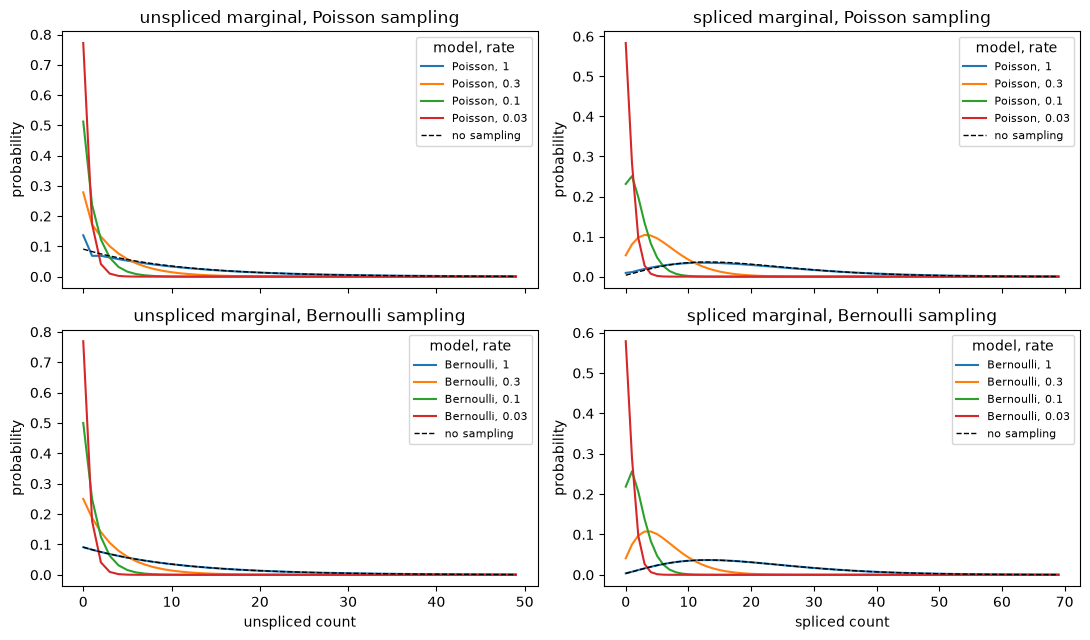

without sampling, exact: mean U 10.00, Fano U 11.00, mean S 20.00, Fano S 7.67; on the 80 x 120 grid: 9.96, 10.73, 20.00, 7.66


,model,rate,mean U,mean U (identity),Fano U,Fano U (identity),mean S,mean S (identity),Fano S,Fano S (identity)
0,Poisson,1.00,9.948,10.0,11.636,12.00,19.999,20.0,8.662,8.667
1,Poisson,0.30,3.000,3.0,4.300,4.30,6.000,6.0,3.300,3.300
2,Poisson,0.10,1.000,1.0,2.100,2.10,2.000,2.0,1.767,1.767
3,Poisson,0.03,0.300,0.3,1.330,1.33,0.600,0.6,1.230,1.230
4,Bernoulli,1.00,9.961,10.0,10.729,11.00,20.000,20.0,7.665,7.667
5,Bernoulli,0.30,3.000,3.0,4.000,4.00,6.000,6.0,3.000,3.000
6,Bernoulli,0.10,1.000,1.0,2.000,2.00,2.000,2.0,1.667,1.667
7,Bernoulli,0.03,0.300,0.3,1.300,1.30,0.600,0.6,1.200,1.200


In [3]:
bursty = CMEModel('Bursty', 'None')
poisson = CMEModel('Bursty', 'Poisson')
bernoulli = CMEModel('Bursty', 'Bernoulli')

b, beta, gamma = 10.0, 1.0, 0.5            # means: U = b/beta = 10, S = b/gamma = 20
p_bio = np.log10([b, beta, gamma])
limits = [80, 120]
rates = [1.0, 0.3, 0.1, 0.03]

def moments(pss):
    u = np.arange(pss.shape[0]); s = np.arange(pss.shape[1])
    pu, ps = pss.sum(1), pss.sum(0)
    mu_u, mu_s = (pu * u).sum(), (ps * s).sum()
    var_u, var_s = (pu * u**2).sum() - mu_u**2, (ps * s**2).sum() - mu_s**2
    return mu_u, var_u / mu_u, mu_s, var_s / mu_s

pss_none = bursty.eval_model_pss(p_bio, limits)
# Reference moments of the bursty model itself (exact): the grid clips its tail slightly.
mu_u0, fano_u0 = b / beta, 1 + b
mu_s0, fano_s0 = b / gamma, 1 + b * beta / (beta + gamma)
mu_u_grid, fano_u_grid, mu_s_grid, fano_s_grid = moments(pss_none)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex='col')
rows = []
for model, name, row in [(poisson, 'Poisson', 0), (bernoulli, 'Bernoulli', 1)]:
    for lam in rates:
        samp = np.log10([lam, lam])        # same sampling parameter for both species here
        pss = model.eval_model_pss(p_bio, limits, samp)
        mu_u, fano_u, mu_s, fano_s = moments(pss)
        excess = fano_u0 if name == 'Poisson' else fano_u0 - 1          # the identities above
        excess_s = fano_s0 if name == 'Poisson' else fano_s0 - 1
        rows.append((name, lam, mu_u, lam * mu_u0, fano_u, 1 + lam * excess,
                     mu_s, lam * mu_s0, fano_s, 1 + lam * excess_s))
        axes[row, 0].plot(pss.sum(1)[:50], label=f'{name}, {lam:g}')
        axes[row, 1].plot(pss.sum(0)[:70], label=f'{name}, {lam:g}')
    for j, (marg, lab) in enumerate([(pss_none.sum(1)[:50], 'unspliced'), (pss_none.sum(0)[:70], 'spliced')]):
        axes[row, j].plot(marg, 'k--', lw=1, label='no sampling')
        axes[row, j].set_ylabel('probability'); axes[row, j].legend(fontsize=8, title='model, rate')
        axes[row, j].set_title(f'{lab} marginal, {name} sampling')
axes[1, 0].set_xlabel('unspliced count'); axes[1, 1].set_xlabel('spliced count')
plt.tight_layout(); plt.savefig('figures/sequencing_noise_marginals.png', dpi=130); plt.show()

tab = pd.DataFrame(rows, columns=['model', 'rate', 'mean U', 'mean U (identity)', 'Fano U', 'Fano U (identity)',
                                  'mean S', 'mean S (identity)', 'Fano S', 'Fano S (identity)'])
print(f'without sampling, exact: mean U {mu_u0:.2f}, Fano U {fano_u0:.2f}, mean S {mu_s0:.2f}, Fano S {fano_s0:.2f}; '
      f'on the {limits[0]} x {limits[1]} grid: {mu_u_grid:.2f}, {fano_u_grid:.2f}, {mu_s_grid:.2f}, {fano_s_grid:.2f}')
tab.round(3)


The numerical moments match the identities; the only visible deviations are at full capture, where the grid clips the tail of the widest distributions. Lowering the sampling rate pushes both marginals toward zero and makes them narrower in absolute terms, but their *shape* relative to the mean changes in a specific way: the excess Fano factor shrinks in proportion to the rate. A bursty gene seen at low capture looks like a gene with a smaller burst size seen at full capture, which is the identifiability problem the sampling grid has to resolve.

---
## 2 · Gene length and the sampling grid

Unspliced molecules are captured through internal poly(A) stretches rather than the poly(A) tail, so the unspliced capture rate of a gene scales with the gene's length. Monod models this by adding $\log_{10}$ of the gene length to the unspliced sampling parameter of each gene: $\lambda_{u,g} = \lambda_u \cdot L_g$. The genome-wide $\lambda_u$ and $\lambda_s$ are the two numbers the sampling grid scans. The length reference is a plain text file with the gene name and its length in the first two columns (the remaining columns, counts of poly(A) runs of each size, are not used).

`extract_data` reads the reference when `transcriptome_filepath` is given and stores `lengths` and `log_lengths` in `.var`; `use_lengths="auto"` then applies the offset for the Poisson model. Genes absent from the reference are dropped.


Gnai3 38867 80 28 14  6  4  4  4  4  4  3  3  3  3  3  2  2  ...
GABAergic cells: (728, 32285) layers: ['matrix', 'spliced', 'unspliced']


250 genes selected; log10 length median 4.77, range 3.74 to 6.47
grid: 6 x 7 = 42 points; log10 lambda_u in [-8, -5], log10 lambda_s in [-3, 0]
effective per-gene log10 lambda_u L across the grid: -4.26 to 1.47


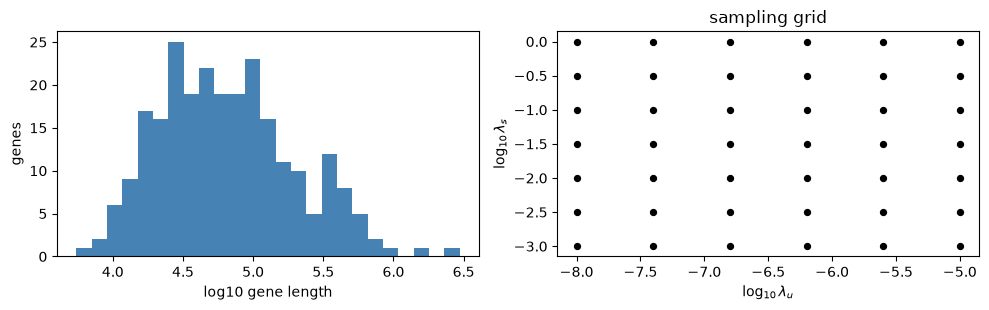

In [4]:
print(open(TX).readline()[:60], '...')

with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)     # duplicate gene names in the file
    gaba_raw = ad.read_h5ad(GABA)
gaba_raw.var_names_make_unique()
print('GABAergic cells:', gaba_raw.shape, 'layers:', list(gaba_raw.layers))

model = CMEModel('Bursty', 'Poisson')
gaba_proc = extract_data(gaba_raw, model, dataset_name='seqnoise_gaba', n_genes=250,
                         transcriptome_filepath=TX, viz=False, seed=1)
genes = list(gaba_proc.var_names)
print(f'{len(genes)} genes selected; log10 length median {gaba_proc.var["log_lengths"].median():.2f}, '
      f'range {gaba_proc.var["log_lengths"].min():.2f} to {gaba_proc.var["log_lengths"].max():.2f}')

ip = InferenceParameters('seqnoise_gaba', model)
grid = np.array(ip.sampl_vals)
print(f'grid: {ip.gridsize[0]} x {ip.gridsize[1]} = {ip.n_grid_points} points; '
      f'log10 lambda_u in [{ip.samp_lb[0]}, {ip.samp_ub[0]}], log10 lambda_s in [{ip.samp_lb[1]}, {ip.samp_ub[1]}]')
eff = grid[:, 0][:, None] + gaba_proc.var['log_lengths'].values[None, :]
print(f'effective per-gene log10 lambda_u L across the grid: {eff.min():.2f} to {eff.max():.2f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(gaba_proc.var['log_lengths'], bins=25, color='steelblue'); ax[0].set_xlabel('log10 gene length'); ax[0].set_ylabel('genes')
ax[1].scatter(grid[:, 0], grid[:, 1], c='k', s=18); ax[1].set_xlabel(r'$\log_{10}\lambda_u$'); ax[1].set_ylabel(r'$\log_{10}\lambda_s$'); ax[1].set_title('sampling grid')
plt.tight_layout(); plt.show()


---
## 3 · The sampling landscape

`perform_inference` fits every gene at every grid point, sums the per-gene divergences into a landscape, and takes the minimum as the sampling optimum. With 250 genes and 42 grid points that is 10,500 fits; on the Rust path they take a few minutes.


In [5]:
t0 = time.time()
gaba = perform_inference(gaba_raw, model, genes_to_fit=genes, n_genes=250, transcriptome_filepath=TX,
                         viz=False, dataset_string='seqnoise_gaba', num_cores=NUM_CORES, seed=1)
print(f'GABAergic fit: {time.time() - t0:.0f} s')
reject_genes(gaba, viz=False)
sr_gaba = search_result_from_uns(gaba.uns['search_result'])
assert list(gaba.var_names) == genes

L = np.asarray(sr_gaba.obj_func).reshape(ip.gridsize)        # rows: lambda_u, columns: lambda_s
print(f'sampling optimum: log10 lambda_u = {sr_gaba.samp_optimum[0]:.2f}, log10 lambda_s = {sr_gaba.samp_optimum[1]:.2f}; '
      f'total KLD {L.min():.2f} (per gene {L.min() / len(genes):.3f})')
print(f'rejected at the optimum: {int(gaba.var["rejected_genes"].sum())} of {len(genes)}')
sr_gaba.find_sampling_optimum(discard_rejected=True)
print(f'optimum from accepted genes only: {np.round(sr_gaba.samp_optimum, 2).tolist()}')
_ = sr_gaba.find_sampling_optimum()   # back to all genes


optimize_genes_2d_sd: 3/250 genes did not converge (3 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 6/250 genes did not converge (6 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 11/250 genes did not converge (11 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 9/250 genes did not converge (9 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 14/250 genes did not converge (14 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


...

optimize_genes_2d_sd: 116/250 genes did not converge (116 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 137/250 genes did not converge (137 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 119/250 genes did not converge (119 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 142/250 genes did not converge (142 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


GABAergic fit: 33 s
sampling optimum: log10 lambda_u = -6.20, log10 lambda_s = -1.00; total KLD 27.87 (per gene 0.111)
rejected at the optimum: 40 of 250
optimum from accepted genes only: [-6.2, -1.0]


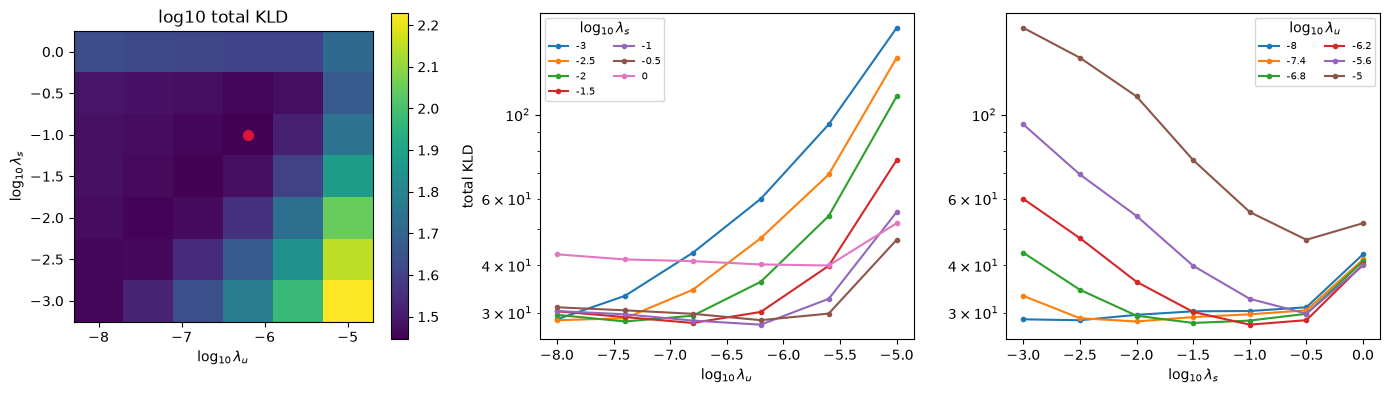

total KLD, rows lambda_u from low to high, columns lambda_s from low to high:
         -3   -2.5     -2  -1.5    -1  -0.5     0
-8     28.8   28.6   29.6  30.2  30.3  31.0  42.8
-7.4   33.2   29.0   28.4  29.2  29.7  30.4  41.4
-6.8   43.2   34.5   29.4  28.2  28.6  29.8  41.0
-6.2   59.9   47.2   36.2  30.1  27.9  28.6  40.2
-5.6   94.2   69.5   54.0  39.9  32.6  29.8  39.9
-5    169.5  141.3  111.7  75.8  55.3  46.7  51.7


In [6]:
lam_u = np.unique(grid[:, 0]); lam_s = np.unique(grid[:, 1])
iu, is_ = np.unravel_index(L.argmin(), L.shape)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sr_gaba.plot_landscape(ax[0], colorbar=True)
ax[0].set_xlabel(r'$\log_{10}\lambda_u$'); ax[0].set_ylabel(r'$\log_{10}\lambda_s$'); ax[0].set_title('log10 total KLD')
for j, ls in enumerate(lam_s):
    ax[1].plot(lam_u, L[:, j], marker='o', ms=3, label=f'{ls:g}')
ax[1].set_xlabel(r'$\log_{10}\lambda_u$'); ax[1].set_ylabel('total KLD'); ax[1].set_yscale('log'); ax[1].legend(title=r'$\log_{10}\lambda_s$', fontsize=7, ncol=2)
for i, lu in enumerate(lam_u):
    ax[2].plot(lam_s, L[i, :], marker='o', ms=3, label=f'{lu:g}')
ax[2].set_xlabel(r'$\log_{10}\lambda_s$'); ax[2].set_yscale('log'); ax[2].legend(title=r'$\log_{10}\lambda_u$', fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('figures/sequencing_noise_landscape.png', dpi=130); plt.show()

print('total KLD, rows lambda_u from low to high, columns lambda_s from low to high:')
print(pd.DataFrame(L, index=[f'{v:g}' for v in lam_u], columns=[f'{v:g}' for v in lam_s]).round(1))


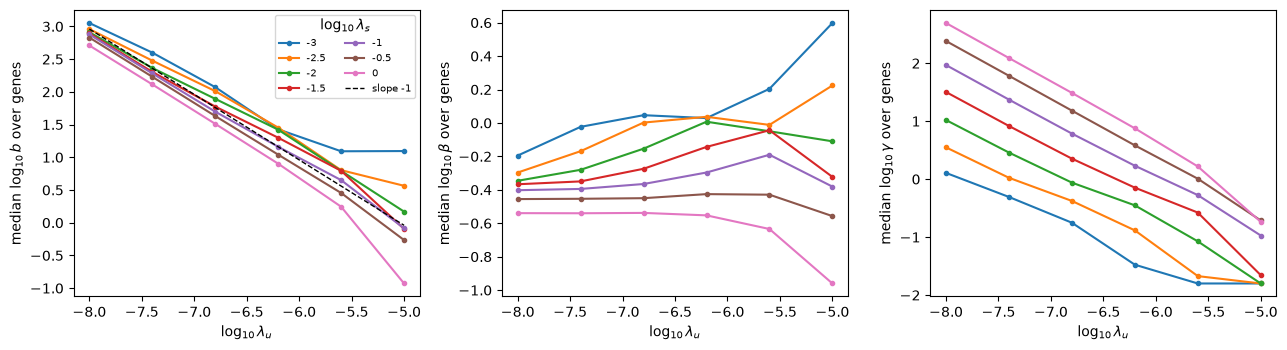

median log10 b against log10 lambda_u at the optimal lambda_s: slope -0.96


In [7]:
# How the fitted parameters move with the sampling parameters.
P = np.asarray(sr_gaba.param_estimates)                 # (grid points, genes, 3): log10 b, beta, gamma
ok = ~sr_gaba.rejected_genes
med = np.median(P[:, ok, :], axis=1).reshape(ip.gridsize[0], ip.gridsize[1], 3)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, name in enumerate([r'$\log_{10} b$', r'$\log_{10}\beta$', r'$\log_{10}\gamma$']):
    for j, ls in enumerate(lam_s):
        ax[k].plot(lam_u, med[:, j, k], marker='o', ms=3, label=f'{ls:g}')
    ax[k].set_xlabel(r'$\log_{10}\lambda_u$'); ax[k].set_ylabel(f'median {name} over genes')
ax[0].plot(lam_u, med[iu, is_, 0] - (lam_u - lam_u[iu]), 'k--', lw=1, label='slope -1')
ax[0].legend(title=r'$\log_{10}\lambda_s$', fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('figures/sequencing_noise_tradeoff.png', dpi=130); plt.show()

slope = np.polyfit(lam_u, med[:, is_, 0], 1)[0]
print(f'median log10 b against log10 lambda_u at the optimal lambda_s: slope {slope:.2f}')


Three things to read off these plots.

**The optimum is interior and the valley is shallow.** The landscape has a diagonal trough running from low capture at both channels to high capture at both. Along it the total divergence changes by a fraction of a percent per gene; across it, by factors. Since every gene's parameters are refitted at every grid point, the trough is exactly the trade-off from section 1 played out over 250 genes.

**Burst size compensates for capture.** The median fitted $\log_{10} b$ falls with slope close to $-1$ against $\log_{10}\lambda_u$: halve the capture rate and the fit doubles the burst size to keep $\lambda_u b$, and with it the unspliced Fano factor, where the data put it. The splicing rate $\beta$ barely moves, because the unspliced mean fixes $\lambda_u b/\beta$ and $\lambda_u b$ is already pinned. The degradation rate $\gamma$ follows $b$ with the same slope, because the spliced mean fixes $\lambda_s b/\gamma$; raising $\lambda_s$ shifts the whole $\gamma$ curve up by the same amount. Every parameter that enters only through a product with a capture rate inherits the trough.

**Higher moments break the tie.** The second moment cannot distinguish the points along the trough, but the full distribution can: a large burst seen at low capture puts more mass at zero and in the tail than a small burst seen at full capture. That shape information is what the KL divergence integrates, and it is weak, which is why the optimum is defined by many genes together and why the grid scan is worth its cost. It is also why the optimum should be checked against the accepted genes only, as above; genes the model does not fit contribute divergence that has nothing to do with sampling.

---
## 4 · Noise decomposition

With the sampling parameters fixed, the observed squared coefficient of variation of a gene splits into three parts. For the bursty model with Poisson sampling, per species with mean molecule number $\mu$ and capture rate $\lambda$:

$$\mathrm{CV}^2_{\text{obs}} = \underbrace{\frac{1}{\mu}}_{\text{intrinsic}} + \underbrace{\frac{\mathrm{Var}(n) - \mu}{\mu^2}}_{\text{extrinsic (bursting)}} + \underbrace{\frac{1}{\lambda\mu}}_{\text{technical}}$$

`CMEModel.eval_model_noise` returns the three fractions for each species from a gene's fitted parameters and its sampling parameters (including the length offset).


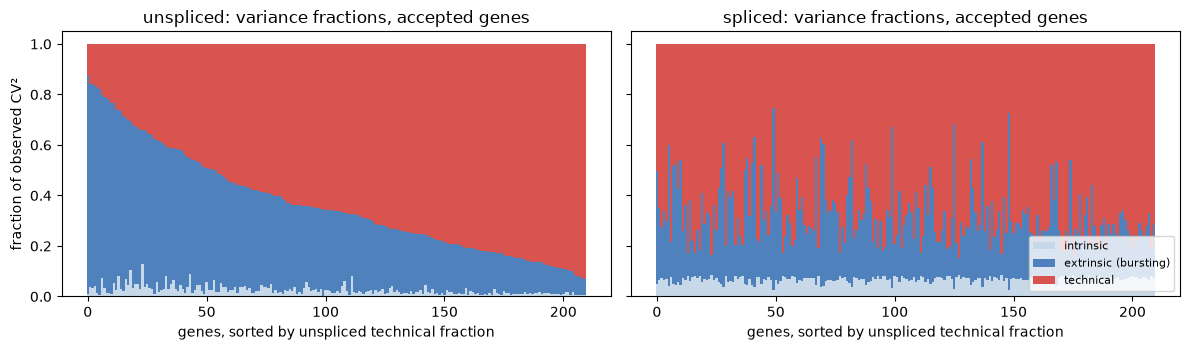

median fractions at the sampling optimum:
           unspliced  spliced
intrinsic      0.019    0.071
extrinsic      0.317    0.220
technical      0.660    0.709


,"grid point (log10 lambda_u, lambda_s)",median technical U,median technical S,median extrinsic U
0,"[-8.0, -3.0]",0.634,0.741,0.365
1,"[-6.2, -1.0]",0.660,0.709,0.317
2,"[-5.0, 0.0]",0.611,0.487,0.053


In [8]:
def noise_fractions(sr, model, k=None):
    # fractions (intrinsic, extrinsic, technical) x species (U, S) for every gene at grid point k
    k = sr.samp_optimum_ind if k is None else k
    P_k, R_k = np.asarray(sr.param_estimates)[k], np.asarray(sr.regressor)[k]
    return np.array([np.asarray(model.eval_model_noise(P_k[g], samp=R_k[g])) for g in range(sr.n_genes)])

F = noise_fractions(sr_gaba, model)                     # (genes, 3, 2)
order = np.argsort(F[ok, 2, 0])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for j, lab in enumerate(['unspliced', 'spliced']):
    frac = F[ok][order, :, j]
    bottom = np.zeros(frac.shape[0])
    for i, (name, col) in enumerate([('intrinsic', '#c7d9e8'), ('extrinsic (bursting)', '#4f81bd'), ('technical', '#d9534f')]):
        ax[j].bar(range(frac.shape[0]), frac[:, i], bottom=bottom, width=1.0, color=col, label=name)
        bottom += frac[:, i]
    ax[j].set_title(f'{lab}: variance fractions, accepted genes'); ax[j].set_xlabel('genes, sorted by unspliced technical fraction')
ax[0].set_ylabel('fraction of observed CV²'); ax[1].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig('figures/sequencing_noise_decomposition.png', dpi=130); plt.show()

summary = pd.DataFrame({'unspliced': np.median(F[ok, :, 0], 0), 'spliced': np.median(F[ok, :, 1], 0)},
                       index=['intrinsic', 'extrinsic', 'technical'])
print('median fractions at the sampling optimum:'); print(summary.round(3))

# The decomposition depends on which grid point you believe.
rows = []
for k in [0, sr_gaba.samp_optimum_ind, ip.n_grid_points - 1]:
    Fk = noise_fractions(sr_gaba, model, k)
    rows.append((np.round(grid[k], 2).tolist(), np.median(Fk[ok, 2, 0]), np.median(Fk[ok, 2, 1]), np.median(Fk[ok, 1, 0])))
pd.DataFrame(rows, columns=['grid point (log10 lambda_u, lambda_s)', 'median technical U', 'median technical S', 'median extrinsic U']).round(3)


At the optimum about two thirds of the observed variance in both channels is technical. The optimum says why: for a gene of median length the unspliced capture rate is $\lambda_u L \approx 0.04$ molecules per read-giving event, and the spliced one is $\lambda_s = 0.1$. Bursting accounts for most of what remains in the unspliced channel, with a wide spread across genes; single-molecule noise is small because the molecule numbers themselves are in the tens.

The table shows how much of this depends on the grid point. The technical share of the unspliced channel hardly moves, since $1/(\lambda\mu)$ is the inverse of the observed mean and every fit reproduces that mean. What moves is the rest: at the high-capture corner the fitted burst sizes are small and bursting is credited with almost none of the unspliced variance, and the spliced technical share drops where the fit itself degrades. A statement about how noisy a gene is in these data is a statement conditional on the landscape minimum, and the biological part of the split is the one at risk.

---
## 5 · Two cell types from one run

The sampling parameters describe the experiment, not the cells, so two cell types from the same run should share them. Fitting both and comparing the landscapes is a check on the whole construction: if the trough runs through the same place for cells with different biology, the model is separating the technical from the biological part as intended. The glutamatergic neurons are fitted with the same 250 genes.


optimize_genes_2d_sd: 9/250 genes did not converge (9 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 13/250 genes did not converge (13 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 17/250 genes did not converge (17 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 16/250 genes did not converge (16 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 23/250 genes did not converge (23 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


...

optimize_genes_2d_sd: 124/250 genes did not converge (124 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 147/250 genes did not converge (147 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 117/250 genes did not converge (117 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 148/250 genes did not converge (148 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


glutamatergic fit: 45 s, 6629 cells
GABAergic optimum     [-6.2, -1.0]
glutamatergic optimum [-6.2, -1.0]
shared optimum (cell-weighted sum of landscapes) [-6.2, -1.0]
most concordant parameters       [-8.0, -3.0]


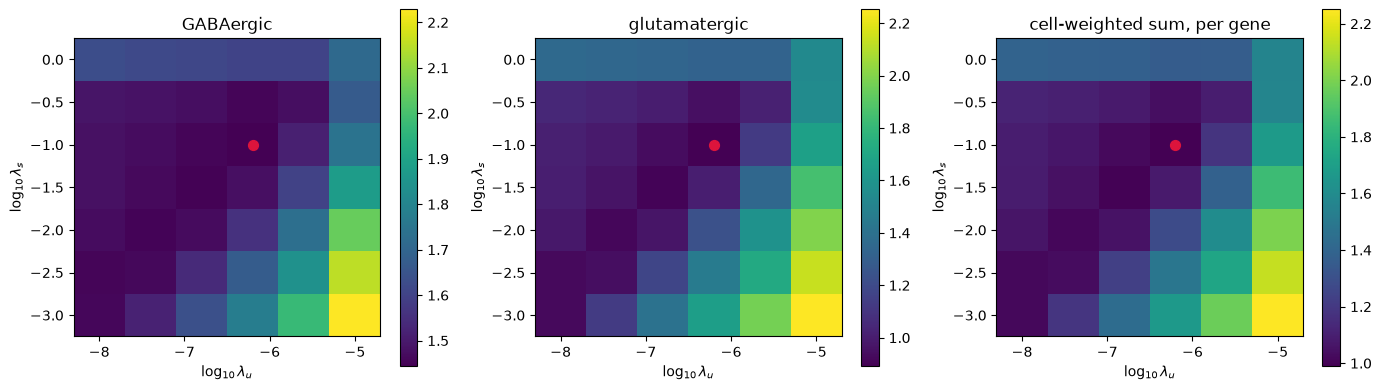

In [9]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)
    glu_raw = ad.read_h5ad(GLU)
glu_raw.var_names_make_unique()
t0 = time.time()
glu = perform_inference(glu_raw, model, genes_to_fit=genes, n_genes=250, transcriptome_filepath=TX,
                        viz=False, dataset_string='seqnoise_glu', num_cores=NUM_CORES, seed=1)
print(f'glutamatergic fit: {time.time() - t0:.0f} s, {glu.n_obs} cells')
reject_genes(glu, viz=False)
sr_glu = search_result_from_uns(glu.uns['search_result'])
assert list(glu.var_names) == genes

L_glu = np.asarray(sr_glu.obj_func).reshape(ip.gridsize)
print(f'GABAergic optimum     {np.round(sr_gaba.samp_optimum, 2).tolist()}')
print(f'glutamatergic optimum {np.round(sr_glu.samp_optimum, 2).tolist()}')
# One point for both: the minimum of the cell-weighted sum of the two landscapes (the joint
# likelihood).  It is set on both results, and find_sampling_optimum keeps it from now on.
shared = find_shared_sampling_optimum([sr_gaba, sr_glu])
k_joint = int(sr_gaba.samp_optimum_ind)
joint = (sr_gaba.n_cells * L + sr_glu.n_cells * L_glu) / (sr_gaba.n_cells + sr_glu.n_cells)
print(f'shared optimum (cell-weighted sum of landscapes) {np.round(shared, 2).tolist()}')
k_conc = analysis.find_most_concordant_samp(sr_gaba, sr_glu)     # sets both results to that point
print(f'most concordant parameters       {np.round(k_conc, 2).tolist()}')

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sr_gaba.set_sampling_optimum(int(L.argmin())); sr_glu.set_sampling_optimum(int(L_glu.argmin()))
sr_gaba.plot_landscape(ax[0], colorbar=True); ax[0].set_title('GABAergic')
sr_glu.plot_landscape(ax[1], colorbar=True); ax[1].set_title('glutamatergic')
im = ax[2].imshow(np.log10(np.flipud(joint.T)), extent=ax[0].images[0].get_extent()); plt.colorbar(im, ax=ax[2])
ax[2].scatter(*grid[k_joint], c='crimson', s=50); ax[2].set_title('cell-weighted sum, per gene')
for a in ax:
    a.set_xlabel(r'$\log_{10}\lambda_u$'); a.set_ylabel(r'$\log_{10}\lambda_s$')
plt.tight_layout(); plt.savefig('figures/sequencing_noise_two_celltypes.png', dpi=130); plt.show()


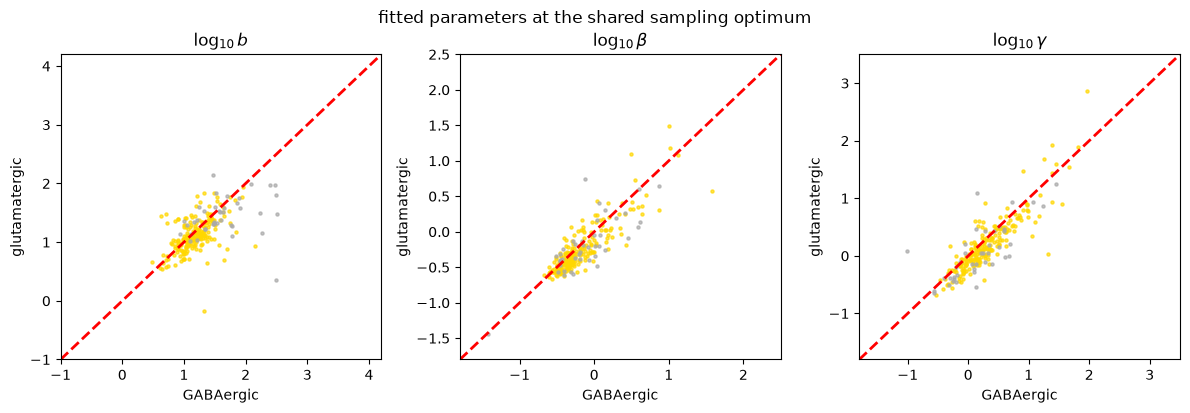

rejected genes: GABAergic 40  glutamatergic 12


In [10]:
# Parameters of the two cell types at the shared optimum.
sr_gaba.set_sampling_optimum(k_joint); sr_glu.set_sampling_optimum(k_joint)
analysis.plot_params_for_pair(sr_gaba, sr_glu, plot_errorbars=False, xlabel='GABAergic', ylabel='glutamatergic',
                              savefig=False)
plt.suptitle('fitted parameters at the shared sampling optimum', y=1.02); plt.show()
print('rejected genes: GABAergic', int(sr_gaba.rejected_genes.sum()), ' glutamatergic', int(sr_glu.rejected_genes.sum()))


The two cell types, fitted independently with nine times as many cells in one as in the other, put their minima at the same grid point, and the summed landscape (each dataset weighted by its cell count, so the sum is the joint likelihood; `find_shared_sampling_optimum` does this and fixes the point on both results) has the same single minimum. That is the construction working as intended: the trough is shaped by the data, the minimum by the experiment. Using one grid point for both results makes the parameter comparison meaningful; the scatter around the identity is what a differential expression analysis would then test (see `analysis_workflow.ipynb`).

`find_most_concordant_samp` picks instead the grid point at which the two parameter sets agree best. Here it chooses the low-capture corner, where both fits have pushed every burst size toward the upper bound and the parameters agree for the wrong reason. It assumes the biology is the same in both datasets, which is not the case for two cell types; prefer the summed landscape. `perform_inference(split_by=...)` applies the same rule to the groups of one object.

---
## 6 · Ambiguous assignments: the third channel

Some reads cannot be assigned to the unspliced or the spliced transcript (they fall in a region shared by both). Quantification pipelines report them as an `ambiguous` layer. Monod can model that layer with `amb_model`: each unspliced (nascent) molecule is counted as ambiguous with probability $p_N$ and each spliced (mature) one with probability $p_M$ (`Unequal`), or with a single $p$ (`Equal`). The probabilities are extra biological parameters, fitted per gene, and the data need a third layer and a third grid limit. This is a model of assignment ambiguity, not of ambient RNA contamination.


parameters: ['b', 'beta', 'gamma', 'p_N', 'p_M']


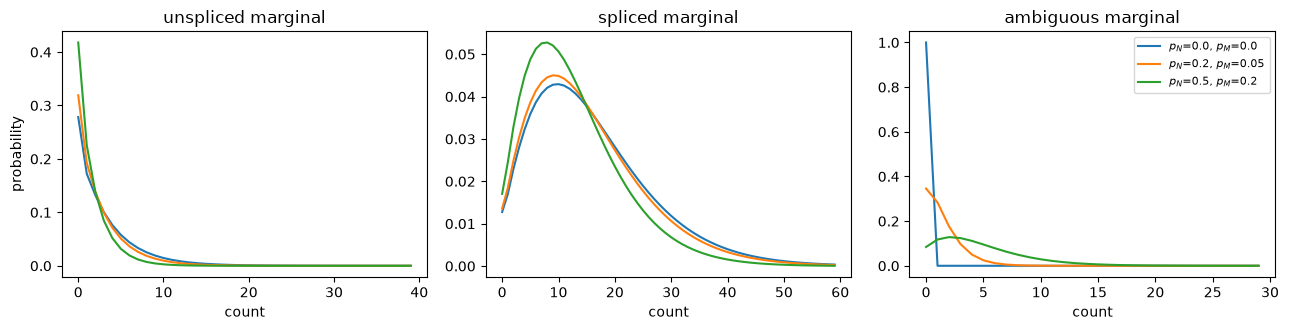

In [11]:
amb = CMEModel('Bursty', 'Poisson', amb_model='Unequal')
print('parameters:', amb.param_names())
samp = np.log10([0.3, 0.8])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for p_n, p_m in [(0.0, 0.0), (0.2, 0.05), (0.5, 0.2)]:
    pss = amb.eval_model_pss(np.concatenate([p_bio, np.log10([max(p_n, 1e-6), max(p_m, 1e-6)])]), [40, 60, 30], samp)
    for j, lab in enumerate(['unspliced', 'spliced', 'ambiguous']):
        ax[j].plot(pss.sum(axis=tuple(i for i in range(3) if i != j)), label=f'$p_N$={p_n}, $p_M$={p_m}')
        ax[j].set_title(f'{lab} marginal'); ax[j].set_xlabel('count')
ax[0].set_ylabel('probability'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


## Summary

- The sequencing models thin the molecule counts; Poisson sampling multiplies the excess Fano factor by the capture rate, so burst size and capture are confounded at the level of second moments.
- The confounding shows up as a diagonal trough in the sampling landscape, with the fitted burst size sliding along it at slope $-1$. The full distributions resolve the trough, weakly per gene and clearly over a few hundred genes; check the optimum against accepted genes only.
- `eval_model_noise` splits each gene's variance into intrinsic, extrinsic and technical parts, conditional on the chosen grid point.
- Cell types from the same run should share a sampling optimum; sum their landscapes rather than fitting each alone or forcing their parameters to agree.
